# 05 — Single-session MOs population dynamics

Prototype session:

- Subject: SWC-038
- Session: 4d8c7767-981c-4347-8e5e-5d5fffe38534
- Region: Secondary motor area
- Whole-session good units: 389
- Valid trials: 545


Main question:

How does visual contrast affect the temporal separation of
left- and right-stimulus representations in MOs population activity?

Analysis workflow:

1. Single-unit raster and PSTH
2. Population response heatmap
3. PCA population trajectories
4. Cross-validated stimulus-side decoding

In [57]:
# Imports and paths

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d


PROJECT_ROOT = Path.cwd().parent

SESSION = (
    "4d8c7767-981c-4347-8e5e-5d5fffe38534"
)
TARGET_REGION=("Secondary motor area")

SESSION_DIR = (
    PROJECT_ROOT
    / "results"
    / "prototype_sessions"
    / SESSION
)


SELECTED_UNITS_PATH = (
    SESSION_DIR
    / "selected_units.csv"
)

ALL_TRIALS_PATH = (
    SESSION_DIR
    / "all_trials_metadata.csv"
)

VALID_TRIALS_PATH = (
    SESSION_DIR
    / "valid_trials_metadata.csv"
)

SPIKE_TIMES_PATH = (
    SESSION_DIR
    / "selected_unit_spike_times.npz"
)

BINNED_SPIKES_PATH = (
    SESSION_DIR
    / "stimulus_aligned_spike_counts.npz"
)


print("Session directory:")
print(SESSION_DIR)

assert SESSION_DIR.exists()

Session directory:
D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\4d8c7767-981c-4347-8e5e-5d5fffe38534


In [59]:
# Figure output configuration

def make_filename_safe(text):

    text = str(text)

    text = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        text,
    )

    return text.strip("_")


REGION_SLUG = make_filename_safe(
    TARGET_REGION
)

SESSION_SHORT = str(
    SESSION
)[:8]


FIGURE_DIR = (
    PROJECT_ROOT
    / "results"
    / "figures"
    / f"{REGION_SLUG}_{SESSION_SHORT}"
)


FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


print(
    "Figure directory:",
    FIGURE_DIR,
)

Figure directory: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767


In [60]:
# Generic figure-saving helper

def save_figure(
    fig,
    figure_name,
    dpi=300,
    save_pdf=True,
):

    safe_name = make_filename_safe(
        figure_name
    )

    png_path = (
        FIGURE_DIR
        / f"{safe_name}.png"
    )

    fig.savefig(
        png_path,
        dpi=dpi,
        bbox_inches="tight",
    )

    print(
        "Saved PNG:",
        png_path,
    )


    if save_pdf:

        pdf_path = (
            FIGURE_DIR
            / f"{safe_name}.pdf"
        )

        fig.savefig(
            pdf_path,
            bbox_inches="tight",
        )

        print(
            "Saved PDF:",
            pdf_path,
        )

In [2]:
# Load unit and trial metadata

selected_units_df = pd.read_csv(
    SELECTED_UNITS_PATH
)

all_trials_df = pd.read_csv(
    ALL_TRIALS_PATH
)

valid_trials_df = pd.read_csv(
    VALID_TRIALS_PATH
)


print(
    "Selected units:",
    selected_units_df.shape,
)

print(
    "All trials:",
    all_trials_df.shape,
)

print(
    "Valid trials:",
    valid_trials_df.shape,
)


display(
    selected_units_df.head()
)

display(
    valid_trials_df[
        [
            "trial_index",
            "gabor_stimulus_onset_time",
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
            "mouse_wheel_choice",
            "is_mouse_rewarded",
            "reaction_time_s",
        ]
    ].head()
)

Selected units: (135, 15)
All trials: (767, 27)
Valid trials: (545, 27)


,unit_index,unit_name,probe_name,ibl_quality_score,kilosort2_label,firing_rate,spike_count,max_electrode_id,region_raw,max_electrode_probe_name,electrode_x,electrode_y,electrode_z,region_parent,is_good_unit
0,1048,probe00_1048,Probe00,1.0,good,0.705961,3970,655,Secondary motor area layer 6a,Probe00,3184.0,2703.0,6717.0,Secondary motor area,True
1,1050,probe00_1050,Probe00,1.0,good,0.425533,2393,656,Secondary motor area layer 6a,Probe00,3179.0,2683.0,6721.0,Secondary motor area,True
2,1051,probe00_1051,Probe00,1.0,good,0.182803,1028,656,Secondary motor area layer 6a,Probe00,3179.0,2683.0,6721.0,Secondary motor area,True
3,1065,probe00_1065,Probe00,1.0,good,5.246517,29504,662,Secondary motor area layer 6a,Probe00,3163.0,2623.0,6724.0,Secondary motor area,True
4,1069,probe00_1069,Probe00,1.0,good,2.015278,11333,663,Secondary motor area layer 6a,Probe00,3163.0,2623.0,6724.0,Secondary motor area,True


,trial_index,gabor_stimulus_onset_time,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded,reaction_time_s
0,0,141.513147,100.00,left,clockwise,True,0.767364
1,2,160.279104,100.00,left,clockwise,True,0.158407
2,3,163.223143,6.25,right,clockwise,False,0.735368
3,4,168.579274,25.00,left,clockwise,True,0.254237
4,5,176.355996,0.00,left,clockwise,True,0.608515


In [3]:
# Load stimulus-aligned binned spike counts

binned_data = np.load(
    BINNED_SPIKES_PATH,
    allow_pickle=False,
)


spike_counts = binned_data[
    "spike_counts"
]

time_bin_edges_s = binned_data[
    "time_bin_edges_s"
]

time_bin_centers_s = binned_data[
    "time_bin_centers_s"
]

binned_trial_indices = binned_data[
    "trial_index"
]

binned_unit_indices = binned_data[
    "unit_index"
]


BIN_SIZE_S = float(
    binned_data[
        "bin_size_s"
    ]
)

TIME_START_S = float(
    binned_data[
        "time_start_s"
    ]
)

TIME_END_S = float(
    binned_data[
        "time_end_s"
    ]
)


print(
    "Spike-count shape:",
    spike_counts.shape,
)

print(
    "Bin size:",
    BIN_SIZE_S,
    "s",
)

print(
    "Time window:",
    TIME_START_S,
    "to",
    TIME_END_S,
    "s",
)

Spike-count shape: (545, 135, 75)
Bin size: 0.02 s
Time window: -0.5 to 1.0 s


In [4]:
# Verify trial and unit ordering

csv_trial_indices = (
    valid_trials_df[
        "trial_index"
    ]
    .astype(int)
    .to_numpy()
)

csv_unit_indices = (
    selected_units_df[
        "unit_index"
    ]
    .astype(int)
    .to_numpy()
)


assert np.array_equal(
    binned_trial_indices,
    csv_trial_indices,
)

assert np.array_equal(
    binned_unit_indices,
    csv_unit_indices,
)

assert spike_counts.shape == (
    len(valid_trials_df),
    len(selected_units_df),
    len(time_bin_centers_s),
)


print(
    "Trial and unit ordering verified."
)

Trial and unit ordering verified.


In [5]:
# Load original spike times for raster plots

spike_time_data = np.load(
    SPIKE_TIMES_PATH,
    allow_pickle=True,
)


raw_spike_unit_indices = (
    spike_time_data[
        "unit_index"
    ]
)

selected_spike_times = (
    spike_time_data[
        "spike_times"
    ]
)


assert np.array_equal(
    raw_spike_unit_indices,
    csv_unit_indices,
)

assert len(
    selected_spike_times
) == len(
    selected_units_df
)


print(
    "Raw spike-time arrays:",
    len(selected_spike_times),
)

print(
    "Spikes in first selected unit:",
    len(selected_spike_times[0]),
)

Raw spike-time arrays: 135
Spikes in first selected unit: 3970


In [6]:
# Convert spike counts to unsmoothed firing rates

firing_rates_hz = (
    spike_counts.astype(
        np.float32
    )
    / BIN_SIZE_S
)


print(
    "Firing-rate shape:",
    firing_rates_hz.shape,
)

print(
    "Raw firing-rate values:",
    np.unique(
        firing_rates_hz
    )[:10],
)

Firing-rate shape: (545, 135, 75)
Raw firing-rate values: [  0.  50. 100. 150. 200. 250. 300. 350.]


In [7]:
# Gaussian temporal smoothing
# Used for visualization and population trajectories.

SMOOTH_SIGMA_S = 0.040

smooth_sigma_bins = (
    SMOOTH_SIGMA_S
    / BIN_SIZE_S
)


smoothed_firing_rates_hz = gaussian_filter1d(
    firing_rates_hz,
    sigma=smooth_sigma_bins,
    axis=2, # trial × unit × time
    mode="nearest",
    truncate=3.0,
)


print(
    "Gaussian sigma:",
    SMOOTH_SIGMA_S,
    "s",
)

print(
    "Gaussian sigma:",
    smooth_sigma_bins,
    "bins",
)

print(
    "Smoothed-rate shape:",
    smoothed_firing_rates_hz.shape,
)

Gaussian sigma: 0.04 s
Gaussian sigma: 2.0 bins
Smoothed-rate shape: (545, 135, 75)


In [8]:
# Valid-trial counts by original contrast and stimulus side

contrast_side_counts = pd.crosstab(
    valid_trials_df[
        "gabor_stimulus_contrast"
    ],
    valid_trials_df[
        "gabor_stimulus_side"
    ],
    margins=True,
)

display(
    contrast_side_counts
)

gabor_stimulus_side,left,right,All
gabor_stimulus_contrast,,,
0.0,37,30,67
6.25,54,60,114
12.5,54,41,95
25.0,76,66,142
100.0,70,57,127
All,291,254,545


In [9]:
# Quantify early visual responses for each unit

baseline_time_mask = (
    (time_bin_centers_s >= -0.30)
    & (time_bin_centers_s < 0.0)
)

early_response_time_mask = (
    (time_bin_centers_s >= 0.05)
    & (time_bin_centers_s < 0.30)
)


contrast_values = pd.to_numeric(
    valid_trials_df[
        "gabor_stimulus_contrast"
    ],
    errors="coerce",
).to_numpy()

stimulus_sides = (
    valid_trials_df[
        "gabor_stimulus_side"
    ]
    .astype(str)
    .str.strip()
    .to_numpy()
)


left_100_trial_mask = (
    (contrast_values == 100.0)
    & (stimulus_sides == "left")
)

right_100_trial_mask = (
    (contrast_values == 100.0)
    & (stimulus_sides == "right")
)


print(
    "100% left trials:",
    int(
        left_100_trial_mask.sum()
    ),
)

print(
    "100% right trials:",
    int(
        right_100_trial_mask.sum()
    ),
)

#指定 trials 和时间窗内，每个 unit 的平均 firing rate
def mean_rate_by_unit(
    rates_hz,
    trial_mask,
    time_mask,
):
    """
    Return one mean firing-rate value per unit.

    Input dimensions:
        trial × unit × time

    Output dimensions:
        unit
    """
    selected_rates = rates_hz[
        trial_mask,
        :,
        :,
    ][:, :, time_mask]

    return selected_rates.mean(
        axis=(0, 2)
    )
#左右刺激的 baseline 和 early response
left_baseline_hz = mean_rate_by_unit(
    firing_rates_hz,
    left_100_trial_mask,
    baseline_time_mask,
)

left_early_hz = mean_rate_by_unit(
    firing_rates_hz,
    left_100_trial_mask,
    early_response_time_mask,
)


right_baseline_hz = mean_rate_by_unit(
    firing_rates_hz,
    right_100_trial_mask,
    baseline_time_mask,
)

right_early_hz = mean_rate_by_unit(
    firing_rates_hz,
    right_100_trial_mask,
    early_response_time_mask,
)


left_evoked_change_hz = (
    left_early_hz
    - left_baseline_hz
)

right_evoked_change_hz = (
    right_early_hz
    - right_baseline_hz
)

#unit level 响应表
unit_response_df = (
    selected_units_df[
        [
            "unit_index",
            "unit_name",
            "probe_name",
            "region_raw",
            "firing_rate",
            "spike_count",
        ]
    ]
    .copy()
)


unit_response_df[
    "baseline_left_100_hz"
] = left_baseline_hz

unit_response_df[
    "early_left_100_hz"
] = left_early_hz

unit_response_df[
    "delta_left_100_hz"
] = left_evoked_change_hz


unit_response_df[
    "baseline_right_100_hz"
] = right_baseline_hz

unit_response_df[
    "early_right_100_hz"
] = right_early_hz

unit_response_df[
    "delta_right_100_hz"
] = right_evoked_change_hz


unit_response_df[
    "max_evoked_increase_100_hz"
] = np.maximum(
    unit_response_df[
        "delta_left_100_hz"
    ],
    unit_response_df[
        "delta_right_100_hz"
    ],
)
#响应最强的
display(
    unit_response_df
    .sort_values(
        "max_evoked_increase_100_hz",
        ascending=False,
    )
    .head(10)
)

100% left trials: 70
100% right trials: 57


,unit_index,unit_name,probe_name,region_raw,firing_rate,spike_count,baseline_left_100_hz,early_left_100_hz,delta_left_100_hz,baseline_right_100_hz,early_right_100_hz,delta_right_100_hz,max_evoked_increase_100_hz
15,1132,probe00_1132,Probe00,Secondary motor area layer 5,18.844889,105975,1.714286,64.450546,62.736259,3.976608,46.018894,42.042286,62.736259
88,2448,probe01_784,Probe01,Secondary motor area layer 5,15.052246,84647,3.285714,52.747253,49.461540,2.982456,39.473682,36.491226,49.461540
89,2512,probe01_848,Probe01,Secondary motor area layer 5,17.055075,95910,1.619048,50.164837,48.545788,2.280702,49.932522,47.651821,48.545788
11,1109,probe00_1109,Probe00,Secondary motor area layer 5,9.308726,52348,1.333333,37.032967,35.699635,1.637427,22.334682,20.697256,35.699635
16,1137,probe00_1137,Probe00,Secondary motor area layer 5,9.520692,53540,8.095238,31.703297,23.608059,9.415205,39.338730,29.923525,29.923525
95,2618,probe01_954,Probe01,Secondary motor area layer 5,12.016617,67576,8.047619,27.527473,19.479855,8.128655,35.357624,27.228970,27.228970
18,1157,probe00_1157,Probe00,Secondary motor area layer 5,10.358421,58251,7.904762,20.219780,12.315018,10.818713,36.842106,26.023392,26.023392
96,2621,probe01_957,Probe01,Secondary motor area layer 5,6.924812,38942,4.952381,30.824175,25.871794,4.152047,20.985155,16.833109,25.871794
40,1268,probe00_1268,Probe00,Secondary motor area layer 5,4.651162,26156,2.285714,25.054945,22.769230,1.052632,4.318489,3.265857,22.769230
90,2571,probe01_907,Probe01,Secondary motor area layer 5,2.215150,12457,0.190476,20.494505,20.304029,0.877193,7.759784,6.882591,20.304029


In [10]:
# Select an example unit using a predefined response criterion

example_unit_position = int(
    unit_response_df[
        "max_evoked_increase_100_hz"
    ]
    .idxmax()
)


example_unit_row = (
    unit_response_df.loc[
        example_unit_position
    ]
)


example_unit_index = int(
    example_unit_row[
        "unit_index"
    ]
)


print(
    "Example unit position in analysis array:",
    example_unit_position,
)

print(
    "Original unit index:",
    example_unit_index,
)

print(
    "Region:",
    example_unit_row[
        "region_raw"
    ],
)

print(
    "Left 100% evoked change:",
    example_unit_row[
        "delta_left_100_hz"
    ],
    "Hz",
)

print(
    "Right 100% evoked change:",
    example_unit_row[
        "delta_right_100_hz"
    ],
    "Hz",
)

Example unit position in analysis array: 15
Original unit index: 1132
Region: Secondary motor area layer 5
Left 100% evoked change: 62.73626 Hz
Right 100% evoked change: 42.042286 Hz


Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\raster.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\raster.pdf


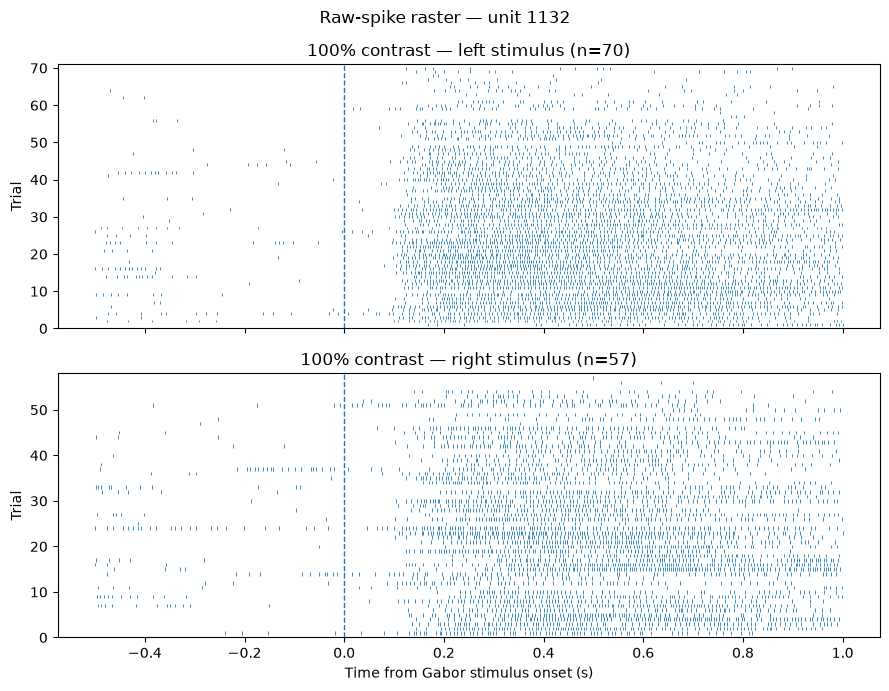

In [61]:
# Raster plot for the example unit
# 100% contrast, separated by stimulus side

example_spike_times_s = np.asarray(
    selected_spike_times[
        example_unit_position
    ],
    dtype=float,
)

stimulus_onset_times_s = pd.to_numeric(
    valid_trials_df[
        "gabor_stimulus_onset_time"
    ],
    errors="coerce",
).to_numpy()


raster_conditions = [
    (
        "100% contrast — left stimulus",
        left_100_trial_mask,
    ),
    (
        "100% contrast — right stimulus",
        right_100_trial_mask,
    ),
]


fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(9, 7),
    sharex=True,
)


for ax, (
    condition_label,
    trial_mask,
) in zip(
    axes,
    raster_conditions,
):

    trial_positions = np.flatnonzero(
        trial_mask
    )

    for raster_row, trial_position in enumerate(
        trial_positions,
        start=1,
    ):

        stimulus_onset_s = (
            stimulus_onset_times_s[
                trial_position
            ]
        )

        absolute_window_start_s = (
            stimulus_onset_s
            + TIME_START_S
        )

        absolute_window_end_s = (
            stimulus_onset_s
            + TIME_END_S
        )


        first_spike_index = np.searchsorted(
            example_spike_times_s,
            absolute_window_start_s,
            side="left",
        )

        last_spike_index = np.searchsorted(
            example_spike_times_s,
            absolute_window_end_s,
            side="left",
        )


        relative_spike_times_s = (
            example_spike_times_s[
                first_spike_index:
                last_spike_index
            ]
            - stimulus_onset_s
        )


        ax.vlines(
            relative_spike_times_s,
            raster_row - 0.4,
            raster_row + 0.4,
            linewidth=0.6,
        )


    ax.axvline(
        0,
        linestyle="--",
        linewidth=1,
    )

    ax.set_ylabel(
        "Trial"
    )

    ax.set_title(
        f"{condition_label} "
        f"(n={len(trial_positions)})"
    )

    ax.set_ylim(
        0,
        len(trial_positions) + 1,
    )


axes[-1].set_xlabel(
    "Time from Gabor stimulus onset (s)"
)

fig.suptitle(
    f"Raw-spike raster — unit {example_unit_index}"
)

plt.tight_layout()

save_figure(
    fig,
    "raster",
)
plt.show()

Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\example_unit_100pct_PSTH.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\example_unit_100pct_PSTH.pdf


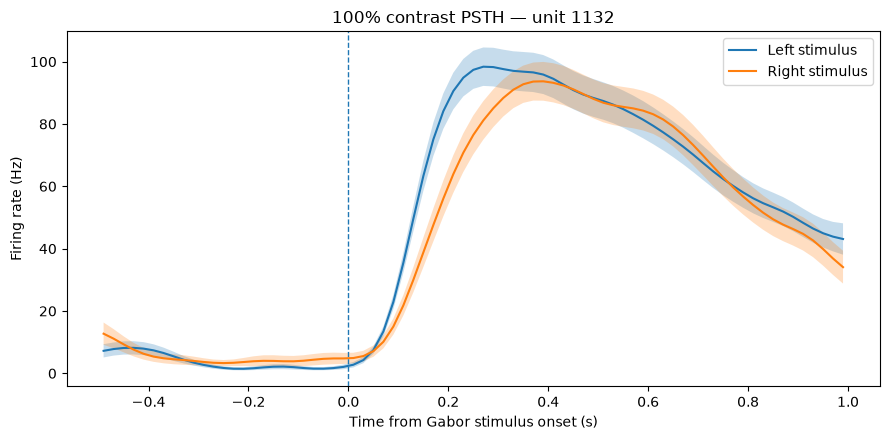

In [62]:
#  Peristimulus Time Histogram (PSTH) for the example unit
# 100% left versus right stimulus

def mean_and_sem(
    values,
):
    """
    values shape:
        trial × time
    """
    mean_values = values.mean(
        axis=0
    )

    sem_values = (
        values.std(
            axis=0,
            ddof=1,
        )
        / np.sqrt(
            values.shape[0]
        )
    )

    return (
        mean_values,
        sem_values,
    )
#left right
left_example_rates_hz = (
    smoothed_firing_rates_hz[
        left_100_trial_mask,
        example_unit_position,
        :,
    ]
)

right_example_rates_hz = (
    smoothed_firing_rates_hz[
        right_100_trial_mask,
        example_unit_position,
        :,
    ]
)


left_mean_hz, left_sem_hz = mean_and_sem(
    left_example_rates_hz
)

right_mean_hz, right_sem_hz = mean_and_sem(
    right_example_rates_hz
)

#plot
plt.figure(
    figsize=(9, 4.5)
)


plt.plot(
    time_bin_centers_s,
    left_mean_hz,
    label="Left stimulus",
)

plt.fill_between(
    time_bin_centers_s,
    left_mean_hz - left_sem_hz,
    left_mean_hz + left_sem_hz,
    alpha=0.25,
)


plt.plot(
    time_bin_centers_s,
    right_mean_hz,
    label="Right stimulus",
)

plt.fill_between(
    time_bin_centers_s,
    right_mean_hz - right_sem_hz,
    right_mean_hz + right_sem_hz,
    alpha=0.25,
)


plt.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel(
    "Time from Gabor stimulus onset (s)"
)

plt.ylabel(
    "Firing rate (Hz)"
)

plt.title(
    f"100% contrast PSTH — unit {example_unit_index}"
)

plt.legend()
plt.tight_layout()

save_figure(
    fig,
   "example_unit_100pct_PSTH",
)
plt.show()

In [13]:
# heatmap
# Define baseline window for population normalization

#更接近刺激前即时状态（边界；刺激后平滑污染）
BASELINE_START_S = -0.35
BASELINE_END_S = -0.15


baseline_mask = (
    (time_bin_centers_s >= BASELINE_START_S)
    & (time_bin_centers_s < BASELINE_END_S)
)


print(
    "Baseline bins:",
    int(baseline_mask.sum()),
)

print(
    "Baseline time centers:",
    time_bin_centers_s[baseline_mask],
)

Baseline bins: 10
Baseline time centers: [-0.35 -0.33 -0.31 -0.29 -0.27 -0.25 -0.23 -0.21 -0.19 -0.17]


In [14]:
#所有trial和unit的baseline
baseline_rates_hz = (
    smoothed_firing_rates_hz[
        :,
        :,
        baseline_mask,
    ]
)


print(
    "Baseline array shape:",
    baseline_rates_hz.shape,
)

Baseline array shape: (545, 135, 10)


In [15]:
#each unit baseline
baseline_mean_hz = (
    baseline_rates_hz
    .mean(
        axis=(0, 2)
    )
)


print(
    "Baseline mean shape:",
    baseline_mean_hz.shape,
)

print(
    "First 10 unit baseline means:",
    baseline_mean_hz[:10],
)

Baseline mean shape: (135,)
First 10 unit baseline means: [0.03035704 0.2416734  0.07740304 5.105728   0.878527   0.47335517
 1.3407469  2.509016   0.08742022 1.2194797 ]


In [16]:
#each unit baseline SD
baseline_std_hz = (
    baseline_rates_hz
    .std(
        axis=(0, 2),
        ddof=1,
    )
)


print(
    "Baseline SD shape:",
    baseline_std_hz.shape,
)

#极小baseline_std_hz
print(
    "Minimum baseline SD:",
    baseline_std_hz.min(),
)

print(
    "Maximum baseline SD:",
    baseline_std_hz.max(),
)

Baseline SD shape: (135,)
Minimum baseline SD: 0.0
Maximum baseline SD: 12.849947


In [18]:
#查看0值
zero_baseline_std_mask = (
    baseline_std_hz <= 1e-12
)

print(
    "Zero baseline-SD units:",
    zero_baseline_std_mask.sum(),
    "/",
    len(baseline_std_hz),
)

zero_baseline_units_df = (
    selected_units_df.loc[
        zero_baseline_std_mask
    ]
    .copy()
)

display(
    zero_baseline_units_df[
        [
            "unit_index",
            "firing_rate",
            "spike_count",
        ]
    ]
)

zero_unit_indices = np.where(
    zero_baseline_std_mask
)[0]

for unit_idx in zero_unit_indices:

    print(
        "Unit:",
        selected_units_df.loc[
            unit_idx,
            "unit_index"
        ]
    )

    print(
        "Baseline mean:",
        baseline_mean_hz[unit_idx]
    )

    print(
        "Baseline SD:",
        baseline_std_hz[unit_idx]
    )

    print(
        "Mean rate across analysis window:",
        smoothed_firing_rates_hz[
            :,
            unit_idx,
            :
        ].mean()
    )

    print(
        "Maximum rate:",
        smoothed_firing_rates_hz[
            :,
            unit_idx,
            :
        ].max()
    )

    print()

Zero baseline-SD units: 3 / 135


,unit_index,firing_rate,spike_count
67,1602,0.147060,827
69,1614,0.221391,1245
73,2241,0.094780,533


Unit: 1602
Baseline mean: 0.0
Baseline SD: 0.0
Mean rate across analysis window: 0.0024464831
Maximum rate: 9.983782

Unit: 1614
Baseline mean: 0.0
Baseline SD: 0.0
Mean rate across analysis window: 0.0085626915
Maximum rate: 18.059969

Unit: 2241
Baseline mean: 0.0
Baseline SD: 0.0
Mean rate across analysis window: 0.0024464831
Maximum rate: 9.983782



In [19]:
# Exclude units with zero baseline SD
# ONLY for baseline z-score analysis

MIN_BASELINE_STD_HZ = 1e-6

valid_z_unit_mask = (
    baseline_std_hz
    >= MIN_BASELINE_STD_HZ
)

print(
    "Original units:",
    len(baseline_std_hz),
)

print(
    "Units retained for z-score:",
    valid_z_unit_mask.sum(),
)

print(
    "Units excluded from z-score:",
    (~valid_z_unit_mask).sum(),
)


# Firing-rate data used ONLY for z-score analysis
smoothed_firing_rates_z_input = (
    smoothed_firing_rates_hz[
        :,
        valid_z_unit_mask,
        :
    ]
)

baseline_mean_z_input = (
    baseline_mean_hz[
        valid_z_unit_mask
    ]
)

baseline_std_z_input = (
    baseline_std_hz[
        valid_z_unit_mask
    ]
)


# Matching unit metadata
z_selected_units_df = (
    selected_units_df.loc[
        valid_z_unit_mask
    ]
    .copy()
    .reset_index(drop=True)
)


print(
    "Z-score input shape:",
    smoothed_firing_rates_z_input.shape,
)

Original units: 135
Units retained for z-score: 132
Units excluded from z-score: 3
Z-score input shape: (545, 132, 75)


In [21]:
# Baseline z-score each retained unit

z_firing_rates = (
    (
        smoothed_firing_rates_z_input
        -
        baseline_mean_z_input[
            None,
            :,
            None,
        ]
    )
    /
    baseline_std_z_input[
        None,
        :,
        None,
    ]
)


print(
    "Z-scored firing-rate shape:",
    z_firing_rates.shape,
)

Z-scored firing-rate shape: (545, 132, 75)


In [22]:
#从trial平均
left_100_population_z = (
    z_firing_rates[
        left_100_trial_mask,
        :,
        :
    ]
    .mean(
        axis=0
    )
)


right_100_population_z = (
    z_firing_rates[
        right_100_trial_mask,
        :,
        :
    ]
    .mean(
        axis=0
    )
)


print(
    "Left heatmap matrix:",
    left_100_population_z.shape,
)

print(
    "Right heatmap matrix:",
    right_100_population_z.shape,
)

Left heatmap matrix: (132, 75)
Right heatmap matrix: (132, 75)


In [23]:
#共同的 100% contrast response
all_100_trial_mask = (
    left_100_trial_mask
    | right_100_trial_mask
)


all_100_population_z = (
    z_firing_rates[
        all_100_trial_mask,
        :,
        :
    ]
    .mean(
        axis=0
    )
)


print(
    all_100_population_z.shape
)
# (40, 75)

(132, 75)


In [24]:
#sort by peak latency

#response window
sorting_response_mask = (
    (time_bin_centers_s >= 0.05)
    & (time_bin_centers_s < 0.40)
)

#提取
sorting_response = (
    all_100_population_z[
        :,
        sorting_response_mask,
    ]
)


print(
    sorting_response.shape
)

peak_bin_within_window = np.argmax(
    sorting_response,
    axis=1,
)

sorting_times_s = (
    time_bin_centers_s[
        sorting_response_mask
    ]
)

peak_latency_s = (
    sorting_times_s[
        peak_bin_within_window
    ]
)

unit_sort_order = np.argsort(
    peak_latency_s
)

(132, 18)


In [25]:
left_100_sorted_z = (
    left_100_population_z[
        unit_sort_order,
        :
    ]
)

right_100_sorted_z = (
    right_100_population_z[
        unit_sort_order,
        :
    ]
)

In [26]:
#color scale
combined_abs_z = np.concatenate(
    [
        np.abs(
            left_100_sorted_z.ravel()
        ),
        np.abs(
            right_100_sorted_z.ravel()
        ),
    ]
)


color_limit = np.percentile(
    combined_abs_z,
    99,
)


print(
    "Symmetric color limit:",
    color_limit,
)

Symmetric color limit: 7.0685663


Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\heatmap_100pct_left_right.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\heatmap_100pct_left_right.pdf


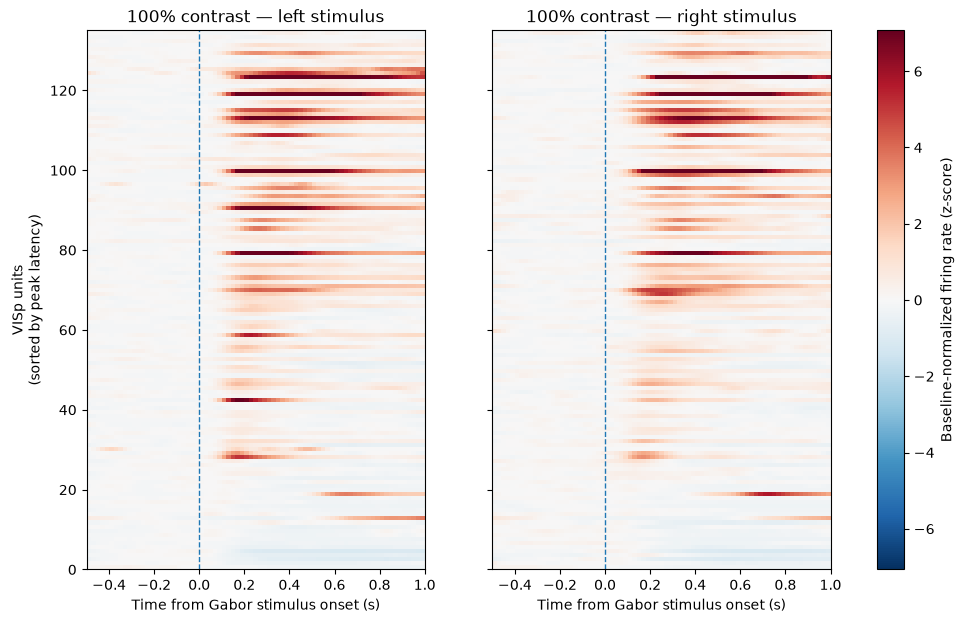

In [63]:
# Population heatmaps
# 100% contrast: left vs right stimulus

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 7),
    sharex=True,
    sharey=True,
)


left_image = axes[0].imshow(
    left_100_sorted_z,
    aspect="auto",
    origin="lower",
    extent=[
        TIME_START_S,
        TIME_END_S,
        0,
        len(selected_units_df),
    ],
    vmin=-color_limit,
    vmax=color_limit,
    cmap="RdBu_r",
)


axes[0].axvline(
    0,
    linestyle="--",
    linewidth=1,
)

axes[0].set_title(
    "100% contrast — left stimulus"
)

axes[0].set_xlabel(
    "Time from Gabor stimulus onset (s)"
)

axes[0].set_ylabel(
    "VISp units\n(sorted by peak latency)"
)


right_image = axes[1].imshow(
    right_100_sorted_z,
    aspect="auto",
    origin="lower",
    extent=[
        TIME_START_S,
        TIME_END_S,
        0,
        len(selected_units_df),
    ],
    vmin=-color_limit,
    vmax=color_limit,
    cmap="RdBu_r",
)


axes[1].axvline(
    0,
    linestyle="--",
    linewidth=1,
)

axes[1].set_title(
    "100% contrast — right stimulus"
)

axes[1].set_xlabel(
    "Time from Gabor stimulus onset (s)"
)


colorbar = fig.colorbar(
    right_image,
    ax=axes,
    label="Baseline-normalized firing rate (z-score)",
)

save_figure(
    fig,
    "heatmap_100pct_left_right",
)

plt.show()

## Population normalization for PCA and trajectory analysis

For population-level analyses, firing rates are baseline-centered and
soft-normalized. All good units are retained, including units with zero
baseline SD, because baseline SD is not used as the normalization denominator.

In [32]:
# Condition-averaged firing rates for population analysis
#
# 4 contrasts × 2 stimulus sides
# Uses ALL selected good units

ANALYSIS_CONTRASTS = [
    6.25,
    12.5,
    25.0,
    100.0,
]

ANALYSIS_SIDES = [
    "left",
    "right",
]


contrast_values = pd.to_numeric(
    valid_trials_df[
        "gabor_stimulus_contrast"
    ],
    errors="coerce",
).to_numpy()

stimulus_sides = (
    valid_trials_df[
        "gabor_stimulus_side"
    ]
    .astype(str)
    .str.strip()
    .to_numpy()
)


condition_mean_rates_hz = {}

for contrast in ANALYSIS_CONTRASTS:

    for side in ANALYSIS_SIDES:

        condition_mask = (
            (contrast_values == contrast)
            &
            (stimulus_sides == side)
        )

        print(
            f"{contrast}% {side}:",
            condition_mask.sum(),
            "trials",
        )

        condition_mean_rates_hz[
            (contrast, side)
        ] = (
            smoothed_firing_rates_hz[
                condition_mask,
                :,
                :
            ]
            .mean(axis=0)
        )

6.25% left: 54 trials
6.25% right: 60 trials
12.5% left: 54 trials
12.5% right: 41 trials
25.0% left: 76 trials
25.0% right: 66 trials
100.0% left: 70 trials
100.0% right: 57 trials


In [35]:
#soft-normalization scale
condition_stack_hz = np.stack(
    [
        condition_mean_rates_hz[
            (contrast, side)
        ]
        for contrast in ANALYSIS_CONTRASTS
        for side in ANALYSIS_SIDES
    ],
    axis=0,
)

print(
    "Condition stack shape:",
    condition_stack_hz.shape,
)

Condition stack shape: (8, 135, 75)


In [36]:
unit_max_rate_hz = (
    condition_stack_hz.max(
        axis=(0, 2)
    )
)

unit_min_rate_hz = (
    condition_stack_hz.min(
        axis=(0, 2)
    )
)

unit_rate_range_hz = (
    unit_max_rate_hz
    -
    unit_min_rate_hz
)


SOFT_NORMALIZATION_HZ = 5.0

soft_scale_hz = (
    unit_rate_range_hz
    +
    SOFT_NORMALIZATION_HZ
)


print(
    "Soft-scale shape:",
    soft_scale_hz.shape,
)

print(
    "Minimum soft scale:",
    soft_scale_hz.min(),
)

Soft-scale shape: (135,)
Minimum soft scale: 5.1512694


In [37]:
#Baseline centering + soft normalization
soft_normalized_condition_rates = (
    (
        condition_stack_hz
        -
        baseline_mean_hz[
            None,
            :,
            None,
        ]
    )
    /
    soft_scale_hz[
        None,
        :,
        None,
    ]
)


print(
    "Soft-normalized condition shape:",
    soft_normalized_condition_rates.shape,
)

print(
    "Any NaN:",
    np.isnan(
        soft_normalized_condition_rates
    ).any(),
)

print(
    "Any Inf:",
    np.isinf(
        soft_normalized_condition_rates
    ).any(),
)

Soft-normalized condition shape: (8, 135, 75)
Any NaN: False
Any Inf: False


In [38]:
#转置为input
pca_input = (
    soft_normalized_condition_rates
    .transpose(
        0,
        2,
        1,
    )
    .reshape(
        -1,
        len(selected_units_df),
    )
)


print(
    "PCA input shape:",
    pca_input.shape,
)

PCA input shape: (600, 135)


In [39]:
from sklearn.decomposition import PCA


pca = PCA(
    n_components=3
)

pca.fit(
    pca_input
);


print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_,
)

print(
    "PC1–3 cumulative variance:",
    pca.explained_variance_ratio_.sum(),
)

Explained variance ratio: [0.57286745 0.14163801 0.06745099]
PC1–3 cumulative variance: 0.78195643


In [41]:
#projection
condition_pca_trajectories = {}

condition_index = 0

for contrast in ANALYSIS_CONTRASTS:

    for side in ANALYSIS_SIDES:

        condition_states = (
            soft_normalized_condition_rates[
                condition_index,
                :,
                :
            ]
            .T
        )

        condition_pca_trajectories[
            (contrast, side)
        ] = pca.transform(
            condition_states
        )

        condition_index += 1

condition_pca_trajectories[
    (100.0, "left")
].shape

(75, 3)

Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\PCA_100pct_left_right.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\PCA_100pct_left_right.pdf


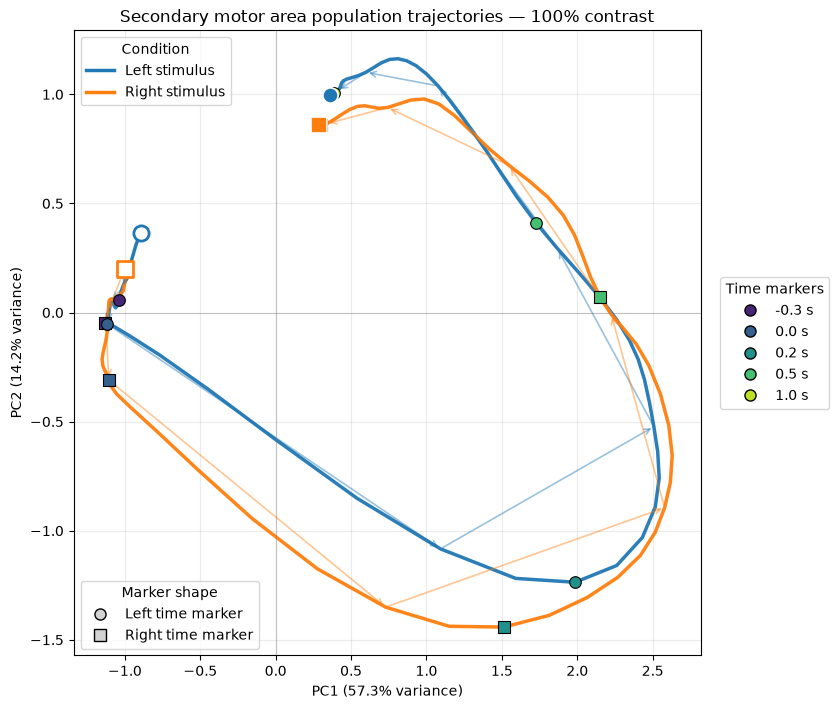

In [64]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt


# ============================================================
# Choose contrast to visualize
# ============================================================

PLOT_CONTRAST = 100.0


left_pca = (
    condition_pca_trajectories[
        (PLOT_CONTRAST, "left")
    ]
)

right_pca = (
    condition_pca_trajectories[
        (PLOT_CONTRAST, "right")
    ]
)

explained_variance_ratio = (
    pca.explained_variance_ratio_
)


# ============================================================
# Helper: nearest time index
# ============================================================

def nearest_time_index(
    time_values,
    target_time,
):
    return int(
        np.argmin(
            np.abs(
                time_values - target_time
            )
        )
    )


# ============================================================
# Choose time markers
# ============================================================

time_markers_s = [
    -0.3,
    0.0,
    0.2,
    0.5,
    0.98,
]

time_marker_indices = [
    nearest_time_index(
        time_bin_centers_s,
        t,
    )
    for t in time_markers_s
]


# Same color = same time point
time_marker_colors = plt.cm.viridis(
    np.linspace(
        0.1,
        0.9,
        len(time_markers_s),
    )
)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(8.5, 7.2)
)


# ------------------------------------------------------------
# Main trajectories
# ------------------------------------------------------------

ax.plot(
    left_pca[:, 0],
    left_pca[:, 1],
    color="tab:blue",
    lw=2.5,
    alpha=0.95,
    label="Left stimulus",
)

ax.plot(
    right_pca[:, 0],
    right_pca[:, 1],
    color="tab:orange",
    lw=2.5,
    alpha=0.95,
    label="Right stimulus",
)


# ------------------------------------------------------------
# Direction arrows
# ------------------------------------------------------------

def add_direction_arrows(
    ax,
    traj,
    color,
    step=8,
):

    for i in range(
        0,
        len(traj) - step,
        step,
    ):

        ax.annotate(
            "",
            xy=(
                traj[i + step, 0],
                traj[i + step, 1],
            ),
            xytext=(
                traj[i, 0],
                traj[i, 1],
            ),
            arrowprops=dict(
                arrowstyle="->",
                color=color,
                lw=1.2,
                alpha=0.45,
            ),
        )


add_direction_arrows(
    ax,
    left_pca,
    "tab:blue",
    step=8,
)

add_direction_arrows(
    ax,
    right_pca,
    "tab:orange",
    step=8,
)


# ------------------------------------------------------------
# Time markers
#
# Same color = same time
# Circle = left
# Square = right
# ------------------------------------------------------------

for (
    marker_color,
    time_idx,
) in zip(
    time_marker_colors,
    time_marker_indices,
):

    ax.scatter(
        left_pca[
            time_idx,
            0,
        ],
        left_pca[
            time_idx,
            1,
        ],
        s=70,
        marker="o",
        facecolor=marker_color,
        edgecolor="black",
        linewidth=0.8,
        zorder=6,
    )

    ax.scatter(
        right_pca[
            time_idx,
            0,
        ],
        right_pca[
            time_idx,
            1,
        ],
        s=70,
        marker="s",
        facecolor=marker_color,
        edgecolor="black",
        linewidth=0.8,
        zorder=6,
    )


# ------------------------------------------------------------
# Highlight start and end points
# ------------------------------------------------------------

ax.scatter(
    left_pca[0, 0],
    left_pca[0, 1],
    s=120,
    marker="o",
    facecolor="white",
    edgecolor="tab:blue",
    linewidth=2.0,
    zorder=7,
)

ax.scatter(
    right_pca[0, 0],
    right_pca[0, 1],
    s=120,
    marker="s",
    facecolor="white",
    edgecolor="tab:orange",
    linewidth=2.0,
    zorder=7,
)


ax.scatter(
    left_pca[-1, 0],
    left_pca[-1, 1],
    s=120,
    marker="o",
    facecolor="tab:blue",
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)

ax.scatter(
    right_pca[-1, 0],
    right_pca[-1, 1],
    s=120,
    marker="s",
    facecolor="tab:orange",
    edgecolor="white",
    linewidth=1.2,
    zorder=7,
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    f"PC1 "
    f"({explained_variance_ratio[0] * 100:.1f}% variance)"
)

ax.set_ylabel(
    f"PC2 "
    f"({explained_variance_ratio[1] * 100:.1f}% variance)"
)

ax.set_title(
    f"{TARGET_REGION} population trajectories — "
    f"{PLOT_CONTRAST:g}% contrast"
)


ax.grid(
    alpha=0.25
)

ax.axhline(
    0,
    color="gray",
    lw=0.8,
    alpha=0.4,
)

ax.axvline(
    0,
    color="gray",
    lw=0.8,
    alpha=0.4,
)


# ------------------------------------------------------------
# Legend 1: condition
# ------------------------------------------------------------

condition_handles = [
    Line2D(
        [0], [0],
        color="tab:blue",
        lw=2.5,
        label="Left stimulus",
    ),
    Line2D(
        [0], [0],
        color="tab:orange",
        lw=2.5,
        label="Right stimulus",
    ),
]

legend1 = ax.legend(
    handles=condition_handles,
    loc="upper left",
    frameon=True,
    title="Condition",
)

ax.add_artist(
    legend1
)


# ------------------------------------------------------------
# Legend 2: marker shape
# ------------------------------------------------------------

shape_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="lightgray",
        markeredgecolor="black",
        markersize=8,
        label="Left time marker",
    ),
    Line2D(
        [0], [0],
        marker="s",
        linestyle="None",
        markerfacecolor="lightgray",
        markeredgecolor="black",
        markersize=8,
        label="Right time marker",
    ),
]

legend2 = ax.legend(
    handles=shape_handles,
    loc="lower left",
    frameon=True,
    title="Marker shape",
)

ax.add_artist(
    legend2
)


# ------------------------------------------------------------
# Legend 3: time-color mapping
# ------------------------------------------------------------

time_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=c,
        markeredgecolor="black",
        markersize=8,
        label=f"{t:.1f} s",
    )
    for c, t in zip(
        time_marker_colors,
        time_markers_s,
    )
]

ax.legend(
    handles=time_handles,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    title="Time markers",
)


plt.tight_layout()

save_figure(
    fig,
    "PCA_100pct_left_right",
)
plt.show()

Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\PCA_all_contrasts_population_trajectories.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\PCA_all_contrasts_population_trajectories.pdf


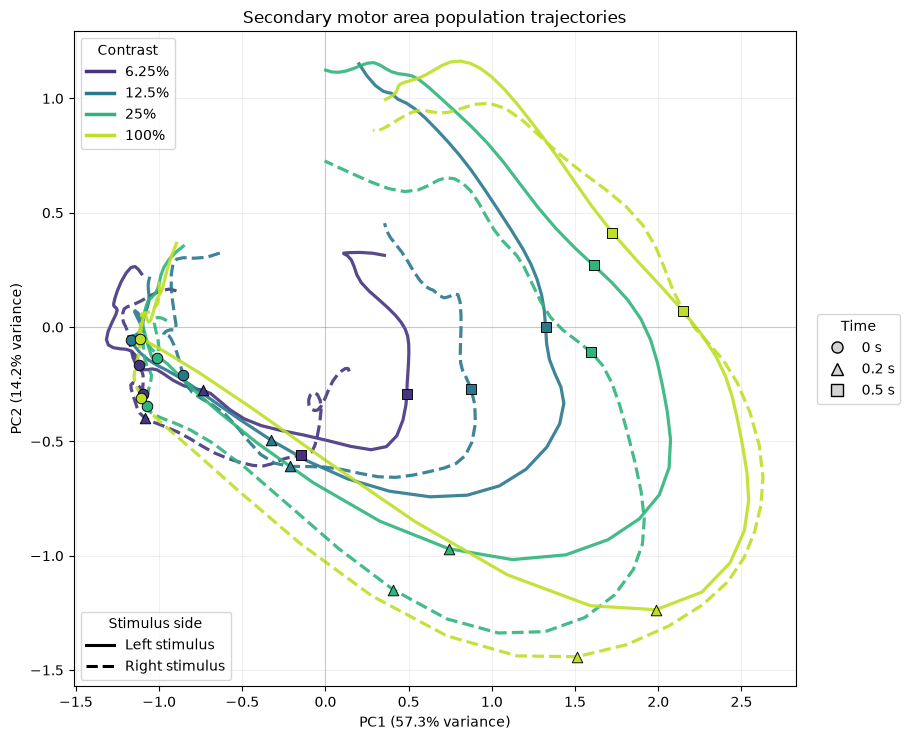

In [65]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np


# ============================================================
# Plot all 8 condition-averaged trajectories
#
# Color     = contrast
# Line style = stimulus side
# Marker    = time
# ============================================================

contrast_colors = plt.cm.viridis(
    np.linspace(
        0.15,
        0.90,
        len(ANALYSIS_CONTRASTS),
    )
)

contrast_color_map = {
    contrast: color
    for contrast, color
    in zip(
        ANALYSIS_CONTRASTS,
        contrast_colors,
    )
}


side_linestyle = {
    "left": "-",
    "right": "--",
}


# ------------------------------------------------------------
# Selected time points
# ------------------------------------------------------------

time_markers_s = [
    0.0,
    0.2,
    0.5,
]

time_marker_shapes = {
    0.0: "o",
    0.2: "^",
    0.5: "s",
}


time_marker_indices = {
    t: int(
        np.argmin(
            np.abs(
                time_bin_centers_s - t
            )
        )
    )
    for t in time_markers_s
}


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(9.2, 7.5)
)


for contrast in ANALYSIS_CONTRASTS:

    color = contrast_color_map[
        contrast
    ]

    for side in ANALYSIS_SIDES:

        trajectory = (
            condition_pca_trajectories[
                (contrast, side)
            ]
        )

        # ----------------------------------------
        # Main trajectory
        # ----------------------------------------

        ax.plot(
            trajectory[:, 0],
            trajectory[:, 1],
            color=color,
            linestyle=side_linestyle[
                side
            ],
            linewidth=2.3,
            alpha=0.90,
        )


        # ----------------------------------------
        # Time markers
        # ----------------------------------------

        for t in time_markers_s:

            idx = time_marker_indices[
                t
            ]

            ax.scatter(
                trajectory[idx, 0],
                trajectory[idx, 1],
                s=58,
                marker=time_marker_shapes[
                    t
                ],
                facecolor=color,
                edgecolor="black",
                linewidth=0.65,
                zorder=5,
            )


# ============================================================
# Axis labels
# ============================================================

ax.set_xlabel(
    f"PC1 "
    f"({pca.explained_variance_ratio_[0] * 100:.1f}% variance)"
)

ax.set_ylabel(
    f"PC2 "
    f"({pca.explained_variance_ratio_[1] * 100:.1f}% variance)"
)

ax.set_title(
    f"{TARGET_REGION} population trajectories"
)


ax.axhline(
    0,
    color="gray",
    linewidth=0.8,
    alpha=0.35,
)

ax.axvline(
    0,
    color="gray",
    linewidth=0.8,
    alpha=0.35,
)

ax.grid(
    alpha=0.18
)


# ============================================================
# Legend 1: contrast
# ============================================================

contrast_handles = [
    Line2D(
        [0],
        [0],
        color=contrast_color_map[
            contrast
        ],
        linewidth=2.5,
        label=f"{contrast:g}%",
    )
    for contrast
    in ANALYSIS_CONTRASTS
]

legend_contrast = ax.legend(
    handles=contrast_handles,
    title="Contrast",
    loc="upper left",
    frameon=True,
)

ax.add_artist(
    legend_contrast
)


# ============================================================
# Legend 2: stimulus side
# ============================================================

side_handles = [
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=2.2,
        linestyle="-",
        label="Left stimulus",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=2.2,
        linestyle="--",
        label="Right stimulus",
    ),
]

legend_side = ax.legend(
    handles=side_handles,
    title="Stimulus side",
    loc="lower left",
    frameon=True,
)

ax.add_artist(
    legend_side
)


# ============================================================
# Legend 3: time
# ============================================================

time_handles = [
    Line2D(
        [0],
        [0],
        marker=time_marker_shapes[
            t
        ],
        linestyle="None",
        markerfacecolor="lightgray",
        markeredgecolor="black",
        markersize=8,
        label=f"{t:g} s",
    )
    for t in time_markers_s
]

ax.legend(
    handles=time_handles,
    title="Time",
    loc="center left",
    bbox_to_anchor=(
        1.02,
        0.5,
    ),
    frameon=True,
)


plt.tight_layout()

save_figure(
    fig,
    "PCA_all_contrasts_population_trajectories",
)

plt.show()

In [47]:
# Build condition-wise soft-normalized population trajectories
# Each trajectory:
# time × unit

condition_soft_trajectories = {}

condition_index = 0

for contrast in ANALYSIS_CONTRASTS:

    for side in ANALYSIS_SIDES:

        condition_soft_trajectories[
            (contrast, side)
        ] = (
            soft_normalized_condition_rates[
                condition_index,
                :,
                :
            ]
            .T
        )

        condition_index += 1


# check
for contrast in ANALYSIS_CONTRASTS:

    print(
        contrast,
        condition_soft_trajectories[
            (contrast, "left")
        ].shape,
    )

6.25 (75, 135)
12.5 (75, 135)
25.0 (75, 135)
100.0 (75, 135)


In [48]:
# Left-right population separation
# Euclidean distance in the FULL soft-normalized neural space

separation_distance = {}

for contrast in ANALYSIS_CONTRASTS:

    left_states = (
        condition_soft_trajectories[
            (contrast, "left")
        ]
    )

    right_states = (
        condition_soft_trajectories[
            (contrast, "right")
        ]
    )

    separation_distance[
        contrast
    ] = np.linalg.norm(
        left_states - right_states,
        axis=1,
    )


for contrast in ANALYSIS_CONTRASTS:

    print(
        contrast,
        separation_distance[
            contrast
        ].shape,
    )

6.25 (75,)
12.5 (75,)
25.0 (75,)
100.0 (75,)


Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\stimulus-side_population_separation_all_contrasts.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\stimulus-side_population_separation_all_contrasts.pdf


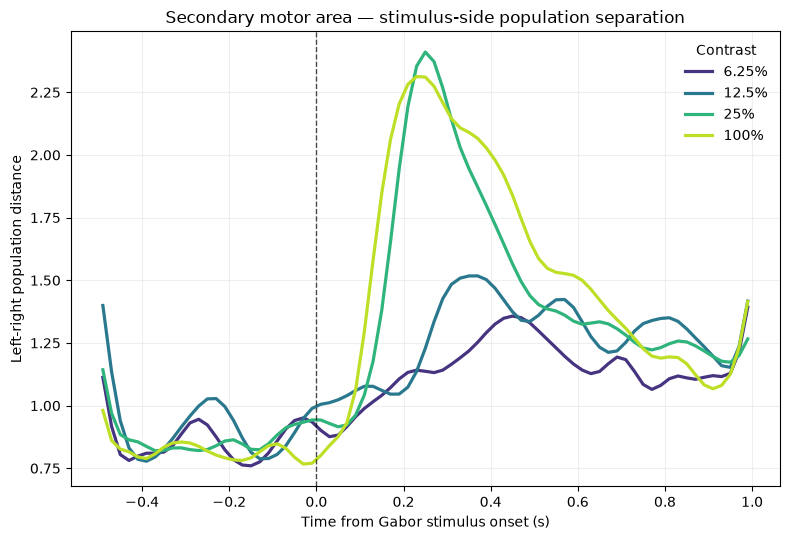

In [69]:
# Plot left-right population separation over time

fig, ax = plt.subplots(
    figsize=(8.0, 5.5)
)


contrast_colors = plt.cm.viridis(
    np.linspace(
        0.15,
        0.90,
        len(ANALYSIS_CONTRASTS),
    )
)


for contrast, color in zip(
    ANALYSIS_CONTRASTS,
    contrast_colors,
):

    ax.plot(
        time_bin_centers_s,
        separation_distance[
            contrast
        ],
        linewidth=2.3,
        color=color,
        label=f"{contrast:g}%",
    )


ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.0,
    alpha=0.7,
)

ax.set_xlabel(
    "Time from Gabor stimulus onset (s)"
)

ax.set_ylabel(
    "Left-right population distance"
)

ax.set_title(
    f"{TARGET_REGION} — stimulus-side population separation"
)

ax.legend(
    title="Contrast",
    frameon=False,
)

ax.grid(
    alpha=0.2
)

plt.tight_layout()
save_figure(
    fig,
    "stimulus-side population_separation_all_contrasts",
)

plt.show()

In [50]:
# Baseline-corrected left-right separation

separation_distance_baseline_corrected = {}

separation_baseline_mean = {}


for contrast in ANALYSIS_CONTRASTS:

    distance = (
        separation_distance[
            contrast
        ]
    )

    baseline_value = (
        distance[
            baseline_mask
        ]
        .mean()
    )

    separation_baseline_mean[
        contrast
    ] = baseline_value

    separation_distance_baseline_corrected[
        contrast
    ] = (
        distance
        -
        baseline_value
    )

Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\stimulus-evoked_population_separation_all_contrasts.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\stimulus-evoked_population_separation_all_contrasts.pdf


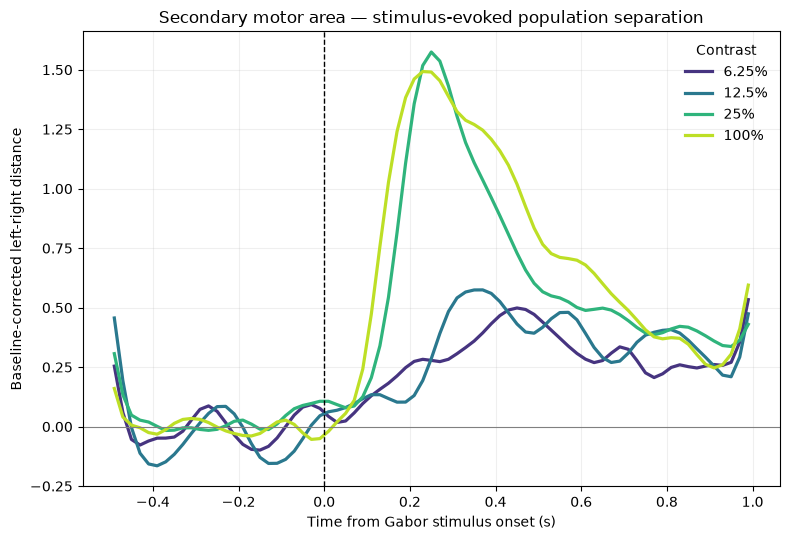

In [68]:
# Plot stimulus-evoked left-right separation

fig, ax = plt.subplots(
    figsize=(8.0, 5.5)
)


for contrast, color in zip(
    ANALYSIS_CONTRASTS,
    contrast_colors,
):

    ax.plot(
        time_bin_centers_s,
        separation_distance_baseline_corrected[
            contrast
        ],
        linewidth=2.3,
        color=color,
        label=f"{contrast:g}%",
    )


ax.axhline(
    0,
    color="gray",
    linewidth=0.8,
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.0,
)


ax.set_xlabel(
    "Time from Gabor stimulus onset (s)"
)

ax.set_ylabel(
    "Baseline-corrected left-right distance"
)

ax.set_title(
    f"{TARGET_REGION} — stimulus-evoked population separation"
)

ax.legend(
    title="Contrast",
    frameon=False,
)

ax.grid(
    alpha=0.2
)

plt.tight_layout()
save_figure(
    fig,
    "stimulus-evoked population_separation_all_contrasts",
)

plt.show()

In [53]:
RESPONSE_START_S = 0.0
RESPONSE_END_S = 0.8
response_mask = (
    (time_bin_centers_s >= 0.0)
    &
    (time_bin_centers_s <= 0.8)
)
# ============================================================
# Summary metrics for left-right separation
# ============================================================

response_mask = (
    (time_bin_centers_s >= 0.0)
    &
    (time_bin_centers_s <= 0.8)
)


separation_summary_rows = []


for contrast in ANALYSIS_CONTRASTS:

    distance = (
        separation_distance_baseline_corrected[
            contrast
        ]
    )

    response_distance = (
        distance[
            response_mask
        ]
    )

    response_times = (
        time_bin_centers_s[
            response_mask
        ]
    )


    peak_index = np.argmax(
        response_distance
    )

    peak_distance = (
        response_distance[
            peak_index
        ]
    )

    peak_time_s = (
        response_times[
            peak_index
        ]
    )

    mean_distance = (
        response_distance.mean()
    )

    auc_distance =np.trapezoid(
    response_distance,
    x=response_times,
)


    separation_summary_rows.append(
        {
            "contrast": contrast,
            "baseline_distance":
                separation_baseline_mean[
                    contrast
                ],
            "peak_evoked_separation":
                peak_distance,
            "peak_time_s":
                peak_time_s,
            "mean_evoked_separation":
                mean_distance,
            "auc_evoked_separation":
                auc_distance,
        }
    )


separation_summary_df = pd.DataFrame(
    separation_summary_rows
)


display(
    separation_summary_df
)

,contrast,baseline_distance,peak_evoked_separation,peak_time_s,mean_evoked_separation,auc_evoked_separation
0,6.25,0.858491,0.498643,0.45,0.284934,0.225298
1,12.50,0.942869,0.574662,0.37,0.330805,0.259974
2,25.00,0.836260,1.574451,0.25,0.684216,0.542361
3,100.00,0.820492,1.492406,0.23,0.816272,0.649524


Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\trajectory_excursion_all_contrasts.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Secondary_motor_area_4d8c7767\trajectory_excursion_all_contrasts.pdf


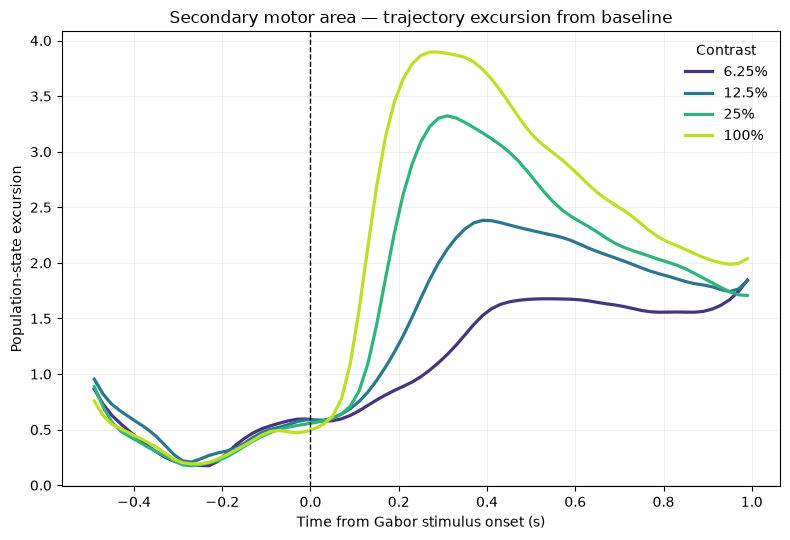

In [70]:
# Trajectory excursion from each condition's baseline centroid

trajectory_excursion = {}


for contrast in ANALYSIS_CONTRASTS:

    for side in ANALYSIS_SIDES:

        trajectory = (
            condition_soft_trajectories[
                (contrast, side)
            ]
        )

        baseline_centroid = (
            trajectory[
                baseline_mask,
                :
            ]
            .mean(axis=0)
        )

        excursion = np.linalg.norm(
            trajectory
            -
            baseline_centroid[
                None,
                :
            ],
            axis=1,
        )

        trajectory_excursion[
            (contrast, side)
        ] = excursion

mean_excursion_by_contrast = {}


for contrast in ANALYSIS_CONTRASTS:

    mean_excursion_by_contrast[
        contrast
    ] = (
        trajectory_excursion[
            (contrast, "left")
        ]
        +
        trajectory_excursion[
            (contrast, "right")
        ]
    ) / 2

fig, ax = plt.subplots(
    figsize=(8.0, 5.5)
)


for contrast, color in zip(
    ANALYSIS_CONTRASTS,
    contrast_colors,
):

    ax.plot(
        time_bin_centers_s,
        mean_excursion_by_contrast[
            contrast
        ],
        color=color,
        linewidth=2.3,
        label=f"{contrast:g}%",
    )


ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.0,
)

ax.set_xlabel(
    "Time from Gabor stimulus onset (s)"
)

ax.set_ylabel(
    "Population-state excursion"
)

ax.set_title(
    f"{TARGET_REGION} — trajectory excursion from baseline"
)

ax.legend(
    title="Contrast",
    frameon=False,
)

ax.grid(
    alpha=0.2
)

plt.tight_layout()
save_figure(
    fig,
    "trajectory_excursion_all_contrasts",
)

plt.show()